### FIT CON UNBINNED MAXIMIZED LIKELIHOOD
Lo scopo è fittare un istogramma (costruito a partire da un dataset fornito da https://www.physi.uni-heidelberg.de/~reygers/lectures/2020/smipp/data_ml_fit.txt).\
Le seguenti celle servono a:
- importare le opportune librerie
- definire la pdf del modello
- caricare il dataset e costruire gli istogrammi

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from iminuit import Minuit
from iminuit.cost import UnbinnedNLL, BinnedNLL

In [4]:
def pdf_unnormalized(x, a, b):
    return 1 + a*x + b*x**2

def pdf_normalized(x, a, b):
    # per normalizzare, integro la pdf tra xmin e xmax, e divido
    num = lambda x: pdf_unnormalized(x, a, b)
    den = (xmax - xmin) + a/2 * (xmax**2 - xmin**2) + b/3 * (xmax**3 - xmin**3)
    return num(x) / den

def cumulative_density_function(x, a, b):
    return np.cumsum(pdf_normalized(x, a, b))

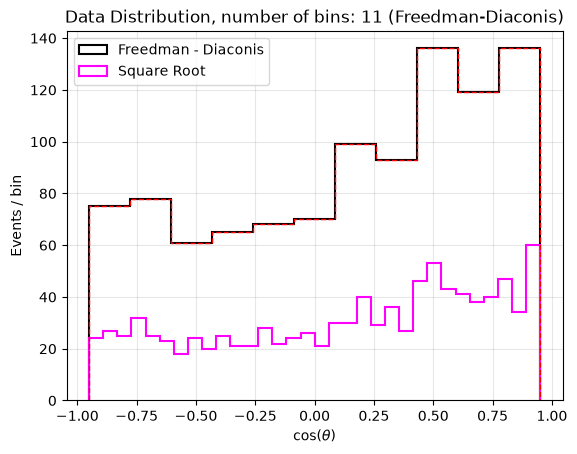

In [68]:
data = np.loadtxt("data.txt")

xmin, xmax = -0.95, 0.95

xfit = np.linspace(xmin, xmax, 500)

# METODO 1
# delta_bin = ???
# edges     = np.arange(xmin, xmax + delta_bin, delta_bin)

# METODO 2
# n_bins    = 20
# edges     = np.linspace(xmin, xmax, n_bins+1)
# xbin      = 0.5 * (edges[:-1] + edges[1:])

# METODO 3 - aggiunge uno step in più: inutile? serve solo se voglio salvarmi i centri dei bin
counts, edges = np.histogram(data, bins='fd', range=(xmin, xmax))
xbin      = 0.5 * (edges[:-1] + edges[1:])


a_true = 0.35
b_true = 0.25

fig, ax = plt.subplots()

# Come si vede dal grafico, entrambi i seguenti metodi coincidono.

# uso il seguente se ho solo i dati e metto automaticamente la regola di binning
ax.hist(data, bins='fd',   range=(xmin, xmax), histtype="step", color="black", linewidth=1.5, label="Freedman - Diaconis")
ax.hist(data, bins='sqrt', range=(xmin, xmax), histtype="step", color="magenta", linewidth=1.5, label="Square Root")

# uso il seguente se produco il binning con una regola fissata via np.histogram
ax.stairs(counts, edges, color='red', linestyle='--', zorder=2)


ax.set(title  = f"Data Distribution, number of bins: {len(xbin)} (Freedman-Diaconis)",
       xlabel = r"cos($\theta$)",
       ylabel =  "Events / bin")
ax.grid(alpha = 0.3)
ax.legend()
plt.show()

La seguente cella serve il solo scopo di visualizzare i dati e la curva fornita (entrambi opportunamente normalizzati) per capire con cosa sto avendo a che fare.\
Tutto per il puro gusto di inserire un po' di bias nell'analisi :)

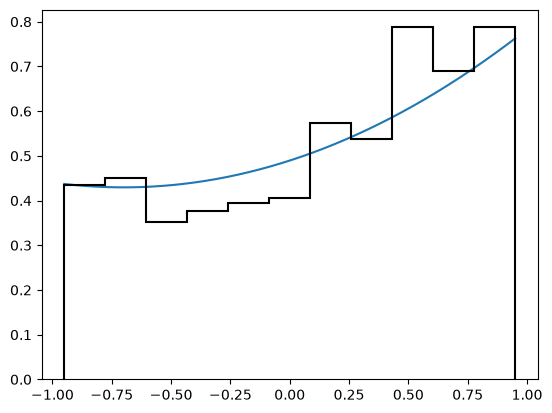

In [50]:
fig, ax = plt.subplots()
ax.plot(xfit, pdf_normalized(xfit, a_true, b_true))
# area = sum(counts) * (edges[1] - edges[0])
# ax.stairs(counts/area, edges)
ax.hist(data, density=True, bins='fd', range=(xmin, xmax), histtype="step", color="black", linewidth=1.5)
plt.show()

### Costruzione della NLL (Negative Log Likelihood)
For independent observations $(x_1,\ldots,x_N)$, the likelihood is\
\
$L(a,b)=\prod_{k=1}^{N} f(x_k\mid a,b)$.\
\
Where f() is the normalized pdf, x_k are all the values in the dataset (`data` _variable, in this notebook_).\
It is numerically more stable to minimize the negative log-likelihood:\
\
$-\log L(a,b)=-\sum_{k=1}^{N}\log f(x_k\mid a,b)$.\
\
`iminuit.cost.UnbinnedNLL` constructs this objective for us. Its model function must return the normalized density evaluated at the observe.\

Se avessi usato la `iminuit.cost.BinnedNLL`, avrei dovuto determinare la CDF di `pdf_normalized()`, e passare `counts` e `edges`.

In [128]:
nll = UnbinnedNLL(data, pdf_normalized)
# nll = BinnedNLL(counts, edges, cumulative_density_function)

m = Minuit(nll, a=0.0, b=0.0) # inizializzo il problema con la funzione costo, e le stime iniziali dei parametri

m.limits["a"] = (0,1)
m.limits["b"] = (0,1)

m.migrad()
m.hesse()
m.minos()

cov  = m.covariance
a, b = m.values

### Analisi dei risultati del fit
La primissima cosa che guardiamo è la **panoramica** offerta da minuit, chiamando semplicemente `m`.\
Successivamente esploriamo la **matrice di correlazione**, e osserviamo la curva con i parametri estratti dal fit, confrontata sui dati e contro il modello con i parametri esatti.\
Poi tracciamo gli **ellissoidi di confidenza**, per esplorare la likelihood a 2 parametri.\
Cosa cambia tra questi ellissoidi, i contorni tracciati dalla matrice di covarianza, e le _"standard deviation ellipses"_?

In [78]:
m

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 1213                       │              Nfcn = 123              │
│ EDM = 4.56e-08 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬──────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼──────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ a    │   0.53    │   0.08    │   -0.07    │    0.08    │    0    │    1    │       │
│ 1 │ b    │   0.51    │   0.16    │   -0.15    │    0.17    │    0    │    1    │       │
└───┴──────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┐
│          │           a           │           b           │
├──────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │   -0.07   │   0.08    │   -0.15   │   0.17    │
│  Valid   │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┘
┌───┬─────────────────┐
│   │       a       b │
├───┼─────────────────┤
│ a │ 0.00571   0.006 │
│ b │   0.006  0.0255 │
└───┴─────────────────┘

In [76]:
m.covariance.correlation()

,a,b
a,1,0.5
b,0.5,1


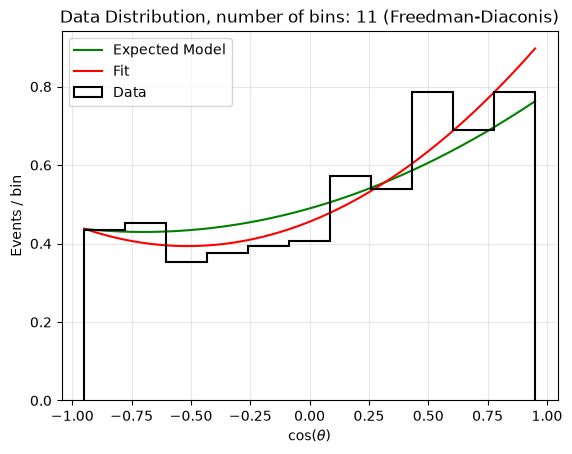

In [69]:
fig, ax = plt.subplots()
ax.plot(xfit, pdf_normalized(xfit, a_true, b_true), color="green", label="Expected Model")
ax.plot(xfit, pdf_normalized(xfit, a, b), color="red", label="Fit")
ax.hist(data, density=True, bins='fd', range=(xmin, xmax), histtype="step", color="black", linewidth=1.5, label="Data")

ax.set(title  = f"Data Distribution, number of bins: {len(xbin)} (Freedman-Diaconis)",
       xlabel = r"cos($\theta$)",
       ylabel =  "Events / bin")
ax.grid(alpha = 0.3)

ax.legend()
plt.show()

#### draw_mnmatrix()
_Da Claude:_\
È la versione “corner plot” di `draw_mncontour`.\
Sulla diagonale disegna i profili MINOS monodimensionali di ogni parametro,\
fuori diagonale i contorni mncontour per tutte le coppie dei parametri liberi.\
Dà un colpo d’occhio completo, ma il costo cresce in fretta.

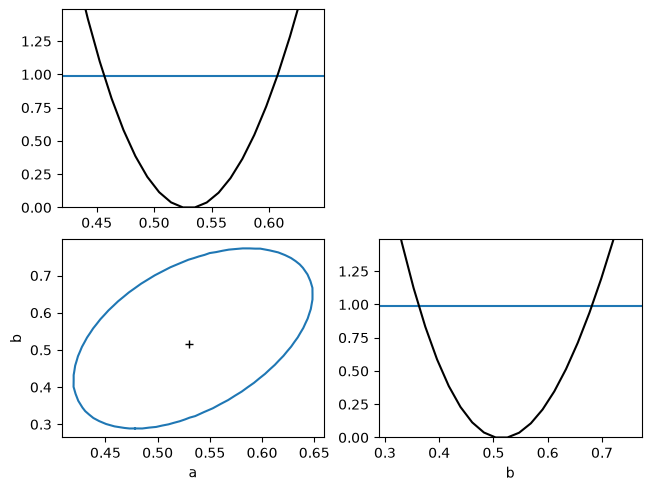

In [82]:
m.draw_mnmatrix();

#### draw_mncontour()
_Da Claude:_\
Calcola con l’algoritmo MINOS i punti del contorno\
$-\ln\mathcal L(x,y,\hat{\hat\theta}(x,y)) = -\ln\mathcal L_{\min} + \Delta,$\
dove per ogni punto del piano gli altri parametri $\hat{\hat\theta}$ sono profilati.\
È la regione di confidenza corretta per la coppia $(x,y)$ anche con parametri di disturbo, e non assume la forma parabolica:\
il contorno può risultare asimmetrico o distorto.\
Il livello $\Delta$ si controlla con l’argomento `cl`.

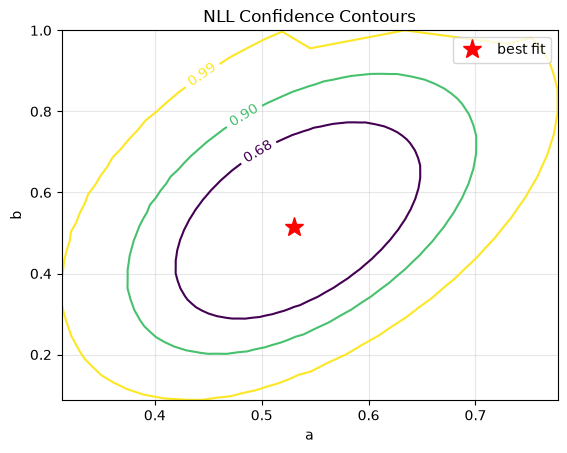

In [166]:
m.draw_mncontour("a", "b", cl=(0.68, 0.9, 0.99), size=100); # perchè compare il kink distorto in alto a destra?
plt.grid(alpha=0.3)
plt.plot(a, b, "r*", ms=14, zorder=5, label="best fit")
plt.title("NLL Confidence Contours")
plt.legend()
plt.show()

#### draw_contour()
_Da Claude:_\
Valuta $-\ln\mathcal L$ su una griglia nel piano $(x,y)$ attorno al minimo e disegna le linee di livello.\
I parametri non coinvolti restano fissi al valore attuale, senza essere rimimizzati.\
Il costo è basso (un numero di valutazioni pari alla dimensione della griglia, per default $50\times50$),\
ma le curve non sono regioni di confidenza in senso proprio, perché ignorano la correlazione con i parametri tenuti fissi.\
Serve soprattutto per vedere la forma della superficie: minimi secondari, valli, non parabolicità.

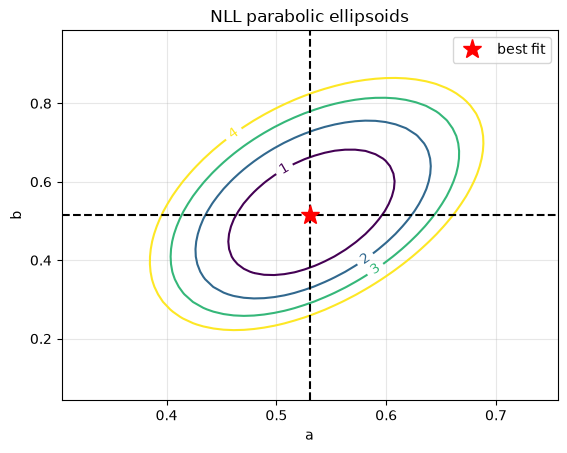

In [162]:
m.draw_contour("a", "b", bound=3);
plt.grid(alpha=0.3)
plt.plot(a, b, "r*", ms=14, zorder=5, label="best fit")
plt.title("NLL parabolic ellipsoids")
plt.legend()
plt.show()

### Test di rappresentazione grafica maggiormente dettagliata 
Il seguente codice è stato sviluppato interamente con IA.

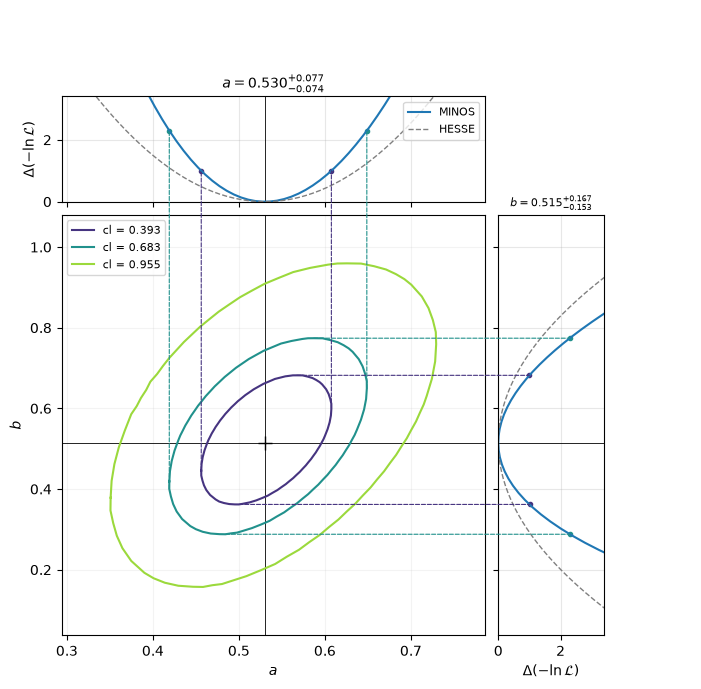

In [124]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import chi2
from matplotlib.patches import ConnectionPatch

# dopo m.migrad(); m.hesse()
a_hat, b_hat = m.values["a"], m.values["b"]
sa, sb = m.errors["a"], m.errors["b"]

# 1) contorni: il primo livello è quello tangente ai profili a ΔNLL = 0.5
cls = [1 - np.exp(-0.5), 0.6827, 0.9545]
contours = [m.mncontour("a", "b", cl=cl, size=80) for cl in cls]

# 2) intervalli di scansione dedotti dal contorno più esterno
out = contours[-1]
pad = 0.15
da, db = np.ptp(out[:, 0]), np.ptp(out[:, 1])
alo, ahi = out[:, 0].min() - pad*da, out[:, 0].max() + pad*da
blo, bhi = out[:, 1].min() - pad*db, out[:, 1].max() + pad*db

# 3) profili MINOS monodimensionali, con minimo sottratto
a_v, nll_a, _ = m.mnprofile("a", size=60, bound=(alo, ahi), subtract_min=True)
b_v, nll_b, _ = m.mnprofile("b", size=60, bound=(blo, bhi), subtract_min=True)

# 4) layout
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(cls)))
levels = [0.5 * chi2.ppf(cl, 2) for cl in cls]      # ΔNLL di ciascun contorno

m.minos()
ma, mb = m.merrors["a"], m.merrors["b"]

fig = plt.figure(figsize=(7, 7))
gs = GridSpec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4],
              hspace=0.05, wspace=0.05, figure=fig)
ax   = fig.add_subplot(gs[1, 0])
ax_t = fig.add_subplot(gs[0, 0], sharex=ax)
ax_r = fig.add_subplot(gs[1, 1], sharey=ax)
ax_t.tick_params(labelbottom=False)
ax_r.tick_params(labelleft=False)

# contorni, proiezioni e livelli
# for c, cl, lev, col in zip(contours, cls, levels, colors):
#     ax.plot(c[:, 0], c[:, 1], color=col, label=f"cl = {cl:.3f}")

#     ea = (c[:, 0].min(), c[:, 0].max())
#     eb = (c[:, 1].min(), c[:, 1].max())

#     for x in ea:                                    # verticali: centro + alto
#         ax.axvline(x, color=col, ls="--", lw=0.7, alpha=0.6)
#         ax_t.axvline(x, color=col, ls="--", lw=0.7, alpha=0.6)
#     for y in eb:                                    # orizzontali: centro + destra
#         ax.axhline(y, color=col, ls="--", lw=0.7, alpha=0.6)
#         ax_r.axhline(y, color=col, ls="--", lw=0.7, alpha=0.6)

#     ax_t.axhline(lev, color=col, ls=":", lw=0.9)    # livelli ΔNLL
#     ax_r.axvline(lev, color=col, ls=":", lw=0.9)
#     ax_t.plot(ea, [lev, lev], "o", color=col, ms=3)
#     ax_r.plot([lev, lev], eb, "o", color=col, ms=3)

# minimo
ax.plot(a_hat, b_hat, "k+", ms=10)
ax.axvline(a_hat, color="k", lw=0.6); ax_t.axvline(a_hat, color="k", lw=0.6)
ax.axhline(b_hat, color="k", lw=0.6); ax_r.axhline(b_hat, color="k", lw=0.6)

def link(axA, xyA, axB, xyB, **kw):
    fig.add_artist(ConnectionPatch(xyA=xyA, coordsA="data", axesA=axA,
                                   xyB=xyB, coordsB="data", axesB=axB, **kw))

for c, cl, lev, col in zip(contours, cls, levels, colors):
    ax.plot(c[:, 0], c[:, 1], color=col, label=f"cl = {cl:.3f}")

    # punti di tangenza: estremi in a (verso il profilo in alto), estremi in b (verso destra)
    for i in (c[:, 0].argmin(), c[:, 0].argmax()):
        xa, yb = c[i]
        pa = np.interp(xa, a_v, nll_a)                 # profilo di a calcolato in xa
        link(ax, (xa, yb), ax_t, (xa, pa), color=col, ls="--", lw=0.8)
        ax_t.plot(xa, pa, "o", color=col, ms=3)

    for j in (c[:, 1].argmin(), c[:, 1].argmax()):
        xa, yb = c[j]
        pb = np.interp(yb, b_v, nll_b)                 # profilo di b calcolato in yb
        link(ax, (xa, yb), ax_r, (pb, yb), color=col, ls="--", lw=0.8)
        ax_r.plot(pb, yb, "o", color=col, ms=3)


# profili MINOS e approssimazione parabolica (HESSE)
ax_t.plot(a_v, nll_a, "C0", label="MINOS")
ax_t.plot(a_v, 0.5 * ((a_v - a_hat) / sa) ** 2, "--", color="gray", lw=1, label="HESSE")
ax_r.plot(nll_b, b_v, "C0")
ax_r.plot(0.5 * ((b_v - b_hat) / sb) ** 2, b_v, "--", color="gray", lw=1)

# limiti ed etichette
dmax = max(levels)
ax.set_xlim(alo, ahi); ax.set_ylim(blo, bhi)
ax_t.set_ylim(0, 1.1 * dmax); ax_r.set_xlim(0, 1.1 * dmax)
ax.set_xlabel("$a$"); ax.set_ylabel("$b$")
ax_t.set_ylabel(r"$\Delta(-\ln\mathcal{L})$")
ax_r.set_xlabel(r"$\Delta(-\ln\mathcal{L})$")
ax_t.set_title(rf"$a={a_hat:.3f}^{{{ma.upper:+.3f}}}_{{{ma.lower:+.3f}}}$", fontsize=10)
ax_r.set_title(rf"$b={b_hat:.3f}^{{{mb.upper:+.3f}}}_{{{mb.lower:+.3f}}}$", fontsize=8)
ax.legend(fontsize=8, loc="upper left")
ax_t.legend(fontsize=8, loc="upper right")
ax.grid(alpha=0.15)
ax_t.grid(alpha=0.3)
ax_r.grid(alpha=0.3)

plt.show()

Quali informazioni ricavo dall'angolo?\
Il fatto che sia compreso tra 0° e 90° significa che a e b hanno correlazione positiva (coerente con quanto si osserva nella matrice di correlazione).\
Che altro si può dire?

┌───┬───────────────┐
│   │      a      b │
├───┼───────────────┤
│ a │ -0.966    0.3 │
│ b │    0.3  0.966 │
└───┴───────────────┘
[0.00416227 0.02708595]
┌───┬─────────────────┐
│   │       a       b │
├───┼─────────────────┤
│ a │ 0.00571   0.006 │
│ b │   0.006  0.0255 │
└───┴─────────────────┘
theta = 74.93678336943937


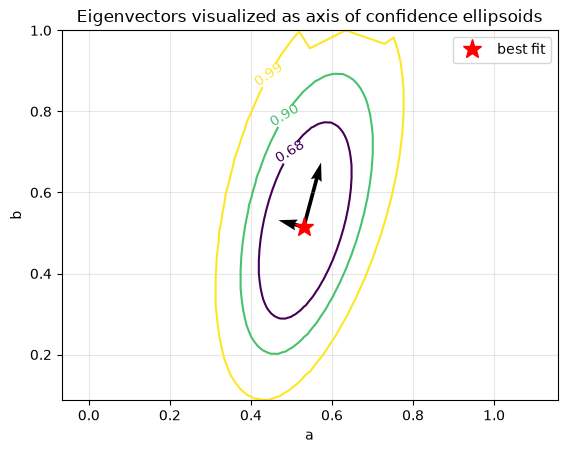

In [165]:
eigenvalues, eigenvectors = np.linalg.eigh(cov)

print(eigenvectors)
print(eigenvalues)
print(cov)

# Gli autovettori sono forniti da np.linalg.eigh(M) come colonne in una matrice.
eig_v1 = eigenvectors[:,0]
eig_v2 = eigenvectors[:,1]

# Pendenza
# arctan(y/x) dell'eig2
angolo = np.arctan(eig_v2[1]/eig_v2[0])
print("theta =", np.degrees(angolo))


# Lo scopo ora è visualizzare gli autovettori sul plot con gli ellissoidi, per capire cosa stiamo osservando.
m.draw_mncontour("a", "b", cl=(0.68, 0.9, 0.99), size=100);
plt.grid(alpha=0.3)
plt.quiver(a, b, *eig_v1 * np.sqrt(eigenvalues[0]), angles="xy", scale_units="xy", scale=1)
plt.quiver(a, b, *eig_v2 * np.sqrt(eigenvalues[1]), angles="xy", scale_units="xy", scale=1)
plt.plot(a, b, "r*", ms=14, zorder=5, label="best fit")
plt.title("Eigenvectors visualized as axis of confidence ellipsoids")
plt.legend()
plt.gca().set_aspect("equal", adjustable="datalim") # consigliato da Claude: serve a riportare il plot del contour sulla stessa scala di quiver (funzione fastidiosa e insidiosa da gestire, personalmente) o viceversa.
plt.show()





### Extra Questions
- Does changing the histogram binning alter the fit? Explain.
- Do different Minuit starting values converge to the same minimum?
- Compare HESSE and MINOS uncertainties. Are the MINOS intervals symmetric?
- Refit a reproducible half-size sample. How do the uncertainties change?
- If the data are the toy sample, compare the fitted values with a = 0.35, b = 0.25.
- Compare the likelihood contours with covariance ellipses. When is the ellipse approximation useful?

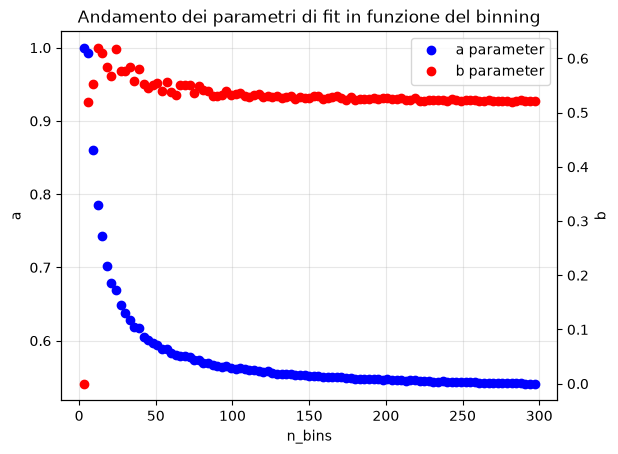

In [20]:
# 1
# No. Il fit è unbinned. 
# Si potrebbe provare con BinnedNLL.
# ciclo for per vari valori di binning: salva un vettore di a, b e plotta in funzione di n_bin.
data = np.loadtxt("data.txt")
xmin, xmax = -0.95, 0.95

def analisi_binned(n_bins):
    counts, edges = np.histogram(data, bins=n_bins, range=(xmin, xmax))
    nll = BinnedNLL(counts, edges, cumulative_density_function)
    
    m = Minuit(nll, a=0.0, b=0.0) # inizializzo il problema con la funzione costo, e le stime iniziali dei parametri
    m.limits["a"] = (0,1)
    m.limits["b"] = (0,1)    
    m.migrad()
    # m.hesse()
    # m.minos()
    return m.values

N = np.asarray([k*3 for k in range(1,100)])
A, B = [], []

for n_bins in N:
    a, b = analisi_binned(n_bins)
    A.append(a)
    B.append(b)
    
A, B = np.asarray(A), np.asarray(B)

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

ax1.plot(N, A, 'o', color="blue", label="a parameter")
ax2.plot(N, B, 'o', color="red",  label="b parameter")

ax1.set_title("Andamento dei parametri di fit in funzione del binning")
ax1.set_xlabel("n_bins")
ax1.set_ylabel("a")
ax2.set_ylabel("b")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2)

ax1.grid(alpha=0.3)
plt.show()

# 2
# testing con diversi valori iniziali. mi aspetto convergenza, sia per robustezza del metodo, che per valori non troppo estremi di a,b. prova tutto.
# inoltre mi aspetto di non osservare divergenze o convergenze errate, poichè il modello ha solo 2 variabili, e la funzione costo è molto semplice (non ho valli/selle/minimi strani).

# 3
# HESSE da errori simmetrici in quanto fa approx parabolica di NLL (cioè assume LH gaussiane).
# MINOS elimina tale ipotesi e trova curve asimmetriche per NLL monodimensionali.

# 4
# serve provare.
# non mi aspetto grandi cambiamenti se passo da 1000 a 500 dati. Se scendo sotto i 200 forse ho prolemi.
# Credo si debba giustificare tenendo d'occhio gli errori poissoniani relativi.

# 5
# non mi è chiaro perchè considerare a = 0.35, b = 0.25.
# mi sembrano valori sbagliati e semplicemente lontani molte sigma dai valori trovati dal fit.

# 6
# cosa cambia tra le due, a livello di definizione?
# le ellissi valgono solo per NLL paraboliche?